In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [70]:
# 1. load data frame differents formates
df_csv=pd.read_csv("sales.csv")
df_xlsx=pd.read_excel("sales.xlsx")
df_json=pd.read_json("sales.json")

In [71]:
# 2. Explore Structure
for name, d in [("csv",df_csv),("excel",df_xlsx),("json",df_json)]:
    print(name,d.shape)
    d.info()
    print(d.isnull().sum())
    print("_"*60)

csv (120, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        120 non-null    int64  
 1   order_date      120 non-null    object 
 2   customer name   119 non-null    object 
 3   product         120 non-null    object 
 4   category        120 non-null    object 
 5   city            120 non-null    object 
 6   region          120 non-null    object 
 7   quantity        119 non-null    float64
 8   unit_price      119 non-null    float64
 9   sales_rep       119 non-null    object 
 10  sales_channel   120 non-null    object 
 11  payment_method  119 non-null    object 
dtypes: float64(2), int64(1), object(9)
memory usage: 11.4+ KB
order_id          0
order_date        0
customer name     1
product           0
category          0
city              0
region            0
quantity          1
unit_price        1
sales_re

In [72]:
df_csv.isnull().sum()

order_id          0
order_date        0
customer name     1
product           0
category          0
city              0
region            0
quantity          1
unit_price        1
sales_rep         1
sales_channel     0
payment_method    1
dtype: int64

In [73]:
# 3. Cleaning

def clean(d):
    d=d.drop_duplicates()
    d.columns=d.columns.str.strip().str.lower().str.replace(" ","_")

    for c in d.select_dtypes("number"):
        d[c]=d[c].fillna(d[c].median())

    for c in d.select_dtypes("object"):
        d[c]=d[c].fillna("Unknown").str.strip().str.title()

    return d

In [74]:
df_csv,df_xlsx,df_json=clean(df_csv),clean(df_xlsx),clean(df_json)

In [75]:
# 4. Unified dataframes
df=pd.concat([df_csv,df_xlsx,df_json],ignore_index=True).drop_duplicates()

In [76]:
# 5. Transformation 
df["order_date"] = pd.to_datetime(df["order_date"],errors="coerce")
df["month"]=df["order_date"].dt.month
df["total_sales"]=df["quantity"]*df["unit_price"]

In [77]:
# 6. Analysis
print(df.describe())
print("Total sales:", df["total_sales"].sum())
print("Average order value:", df["total_sales"].mean())
print(df.groupby("category")["total_sales"].sum()) 

          order_id                     order_date    quantity    unit_price  \
count   360.000000                            360  360.000000    360.000000   
mean   1180.500000  2024-07-04 06:44:00.000000256   10.819444  15374.102028   
min    1001.000000            2024-01-02 00:00:00    1.000000     17.960000   
25%    1090.750000            2024-03-27 12:00:00    3.000000    536.495000   
50%    1180.500000            2024-07-14 00:00:00    6.000000   9859.015000   
75%    1270.250000            2024-10-03 06:00:00   11.000000  26607.940000   
max    1360.000000            2024-12-31 00:00:00   79.000000  66434.430000   
std     104.067286                            NaN   13.888259  16677.752908   

            month    total_sales  
count  360.000000     360.000000  
mean     6.619444   67415.204722  
min      1.000000     236.650000  
25%      3.000000    5578.800000  
50%      7.000000   33950.915000  
75%     10.000000   93428.070000  
max     12.000000  465041.010000  
std     

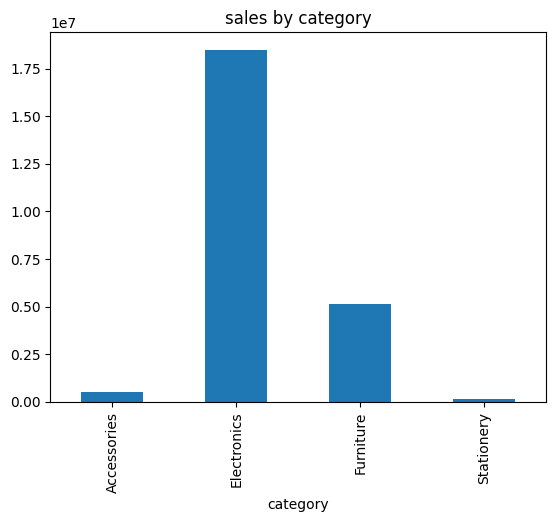

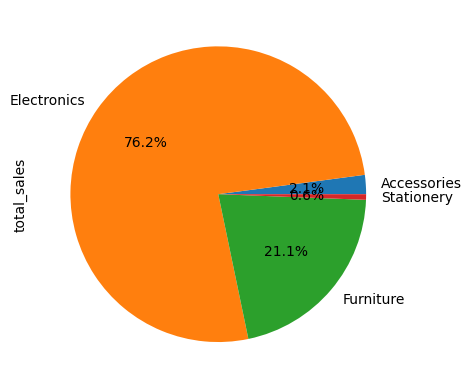

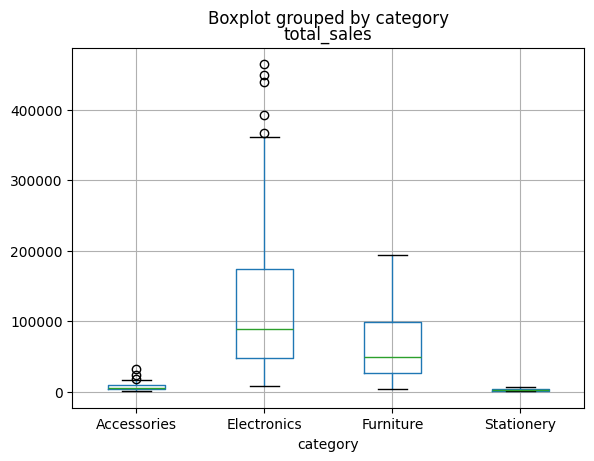

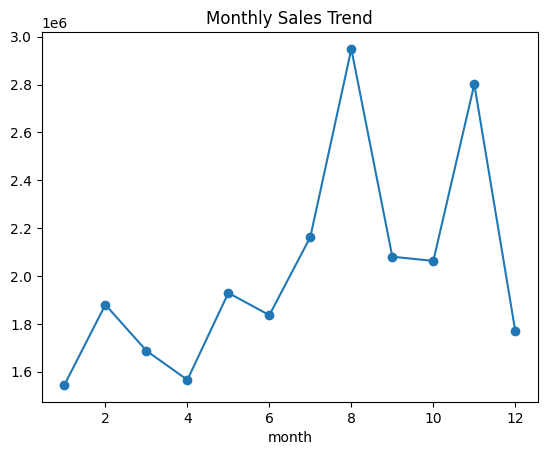

In [78]:
# 7. Visualization
df.groupby("category")["total_sales"].sum().plot(kind="bar",title="sales by category")
plt.show()

df.groupby("category")["total_sales"].sum().plot(kind="pie",autopct="%1.1f%%")
plt.show()

df.boxplot(column="total_sales", by="category")
plt.show()

df.groupby("month")["total_sales"].sum().plot(marker="o", title="Monthly Sales Trend")
plt.show()